In [1]:
import os, glob
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

device = "cuda" if torch.cuda.is_available() else "cpu"
class_names = ["meningioma", "glioma", "pituitary"]

saved = torch.load(glob.glob("/kaggle/input/**/slices_224.pt", recursive=True)[0])
X, y = saved["X"].float(), saved["y"]

csv_path = glob.glob("/kaggle/input/**/*slice_info*.csv", recursive=True)[0]
df = pd.read_csv(csv_path, dtype={"slice_id": str, "pid": str})
if "slice_ids" in saved:
    df = df.set_index("slice_id").loc[saved["slice_ids"]].reset_index()

assert len(df) == len(X) == len(y)
assert (df["label"].to_numpy() - 1 == y.numpy()).all(), "rows of X and the CSV don't line up"
idx = {s: np.where(df["split"] == s)[0] for s in ["train", "val", "test"]}
print(X.shape, {k: len(v) for k, v in idx.items()})

torch.Size([3064, 1, 224, 224]) {'train': 2449, 'val': 365, 'test': 250}


In [2]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

class SliceDataset(Dataset):
    def __init__(self, indices):
        self.indices = indices
    def __len__(self):
        return len(self.indices)
    def __getitem__(self, i):
        j = self.indices[i]
        return (X[j].repeat(3, 1, 1) - MEAN) / STD, y[j]

def predict(model, indices):
    dl = DataLoader(SliceDataset(indices), batch_size=64)
    model.eval()
    probs = []
    with torch.no_grad():
        for xb, _ in dl:
            probs.append(F.softmax(model(xb.to(device)), dim=1).cpu())
    return torch.cat(probs).numpy()

ckpt = glob.glob("/kaggle/input/**/resnet18_best.pth", recursive=True)[0]
baseline = models.resnet18()
baseline.fc = nn.Linear(baseline.fc.in_features, 3)
baseline.load_state_dict(torch.load(ckpt, map_location="cpu"))
baseline = baseline.to(device)

In [3]:
val_probs = predict(baseline, idx["val"])
val_true = y[idx["val"]].numpy()
print("val accuracy:", round(float((val_probs.argmax(1) == val_true).mean()), 3))
print(classification_report(val_true, val_probs.argmax(1), target_names=class_names, digits=3))

val accuracy: 0.951
              precision    recall  f1-score   support

  meningioma      0.844     0.950     0.894        80
      glioma      1.000     0.927     0.962       177
   pituitary      0.964     0.991     0.977       108

    accuracy                          0.951       365
   macro avg      0.936     0.956     0.944       365
weighted avg      0.955     0.951     0.952       365



In [4]:
val_df = df.iloc[idx["val"]].copy()
val_df["true"], val_df["pred"] = val_true, val_probs.argmax(1)
errors = val_df[val_df.true != val_df.pred]
print(errors.groupby(["pid", "class_name"]).size().sort_values(ascending=False))

pid        class_name
100820     glioma        10
107494     meningioma     3
MR017260F  glioma         2
103925     meningioma     1
110518     pituitary      1
MR040240   glioma         1
dtype: int64


In [5]:
def patient_vote(sub_df, probs):
    t = pd.DataFrame(probs, columns=[0, 1, 2])
    t["pid"], t["true"] = sub_df["pid"].values, sub_df["label"].values - 1
    g = t.groupby("pid").agg({0: "mean", 1: "mean", 2: "mean", "true": "first"})
    pred = g[[0, 1, 2]].values.argmax(1)
    return (pred == g["true"].values).mean(), len(g), g.assign(pred=pred)

def bootstrap_ci(sub_df, probs, n=1000, seed=0):
    rng = np.random.default_rng(seed)
    correct = pd.Series((probs.argmax(1) == sub_df["label"].values - 1).astype(float))
    grp = correct.groupby(sub_df["pid"].values)
    sums, counts = grp.sum().values, grp.count().values
    accs = []
    for _ in range(n):
        pick = rng.integers(0, len(sums), len(sums))
        accs.append(sums[pick].sum() / counts[pick].sum())
    return np.percentile(accs, [2.5, 97.5])

pacc, npat, _ = patient_vote(val_df, val_probs)
print(f"val patient-level accuracy: {pacc:.3f} on {npat} patients")
print("95% interval for slice accuracy:", bootstrap_ci(val_df, val_probs).round(3))

val patient-level accuracy: 0.957 on 23 patients
95% interval for slice accuracy: [0.882 0.989]


17 slices; 10 wrong


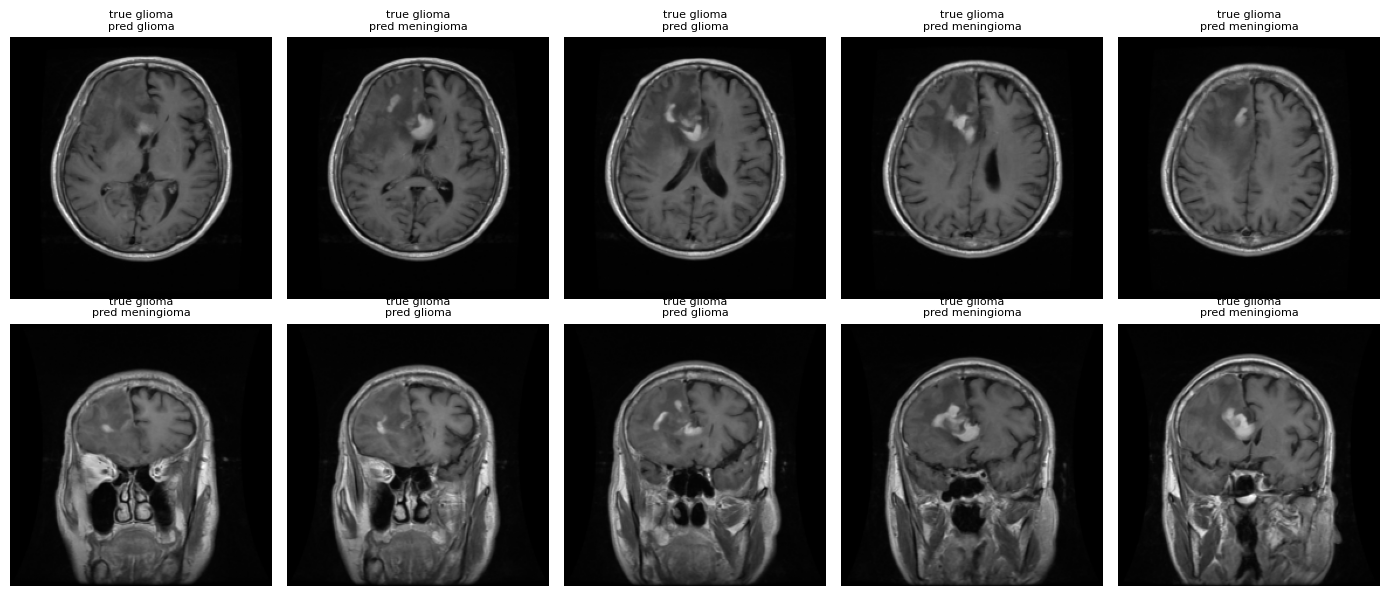

In [6]:
pid_to_check = "100820"
rows = val_df[val_df.pid == pid_to_check]
print(len(rows), "slices;", (rows.true != rows.pred).sum(), "wrong")

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax in axes.ravel():
    ax.axis("off")
for ax, (i, r) in zip(axes.ravel(), rows.head(10).iterrows()):
    ax.imshow(X[i, 0], cmap="gray")
    ax.set_title(f"true {class_names[r.true]}\npred {class_names[r.pred]}", fontsize=8)
plt.tight_layout()
plt.show()

23 slices; 2 wrong


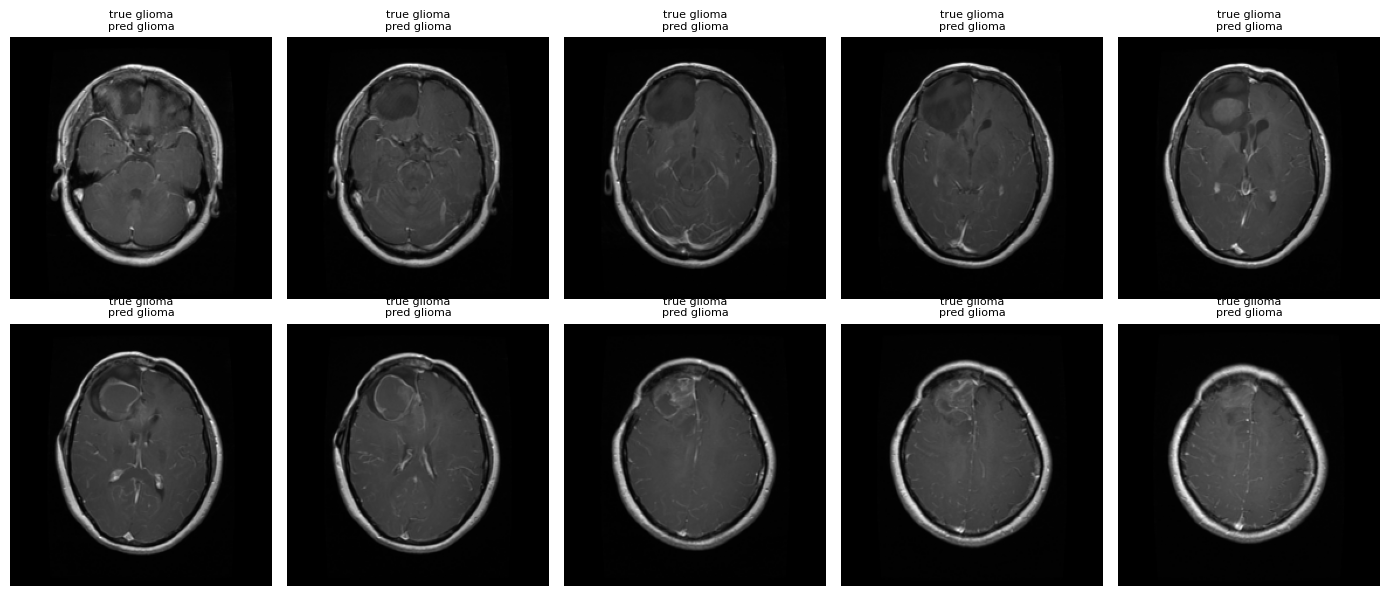

In [7]:
pid_to_check = "MR017260F"
rows = val_df[val_df.pid == pid_to_check]
print(len(rows), "slices;", (rows.true != rows.pred).sum(), "wrong")

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax in axes.ravel():
    ax.axis("off")
for ax, (i, r) in zip(axes.ravel(), rows.head(10).iterrows()):
    ax.imshow(X[i, 0], cmap="gray")
    ax.set_title(f"true {class_names[r.true]}\npred {class_names[r.pred]}", fontsize=8)
plt.tight_layout()
plt.show()

In [8]:
for d in (df, val_df):
    d["id_format"] = np.where(d["pid"].str.startswith("MR"), "MR-prefixed", "numeric")
val_df["correct"] = val_df.true == val_df.pred

print(pd.crosstab(df["id_format"], df["class_name"]))
print(val_df.groupby("id_format").agg(patients=("pid", "nunique"),
                                      slices=("pid", "size"),
                                      accuracy=("correct", "mean")))

class_name   glioma  meningioma  pituitary
id_format                                 
MR-prefixed    1221           0          0
numeric         205         708        930
             patients  slices  accuracy
id_format                              
MR-prefixed         8     160  0.981250
numeric            15     205  0.926829


              precision    recall  f1-score   support

  meningioma      0.892     0.767     0.825        43
      glioma      0.963     0.954     0.958       108
   pituitary      0.934     1.000     0.966        99

    accuracy                          0.940       250
   macro avg      0.929     0.907     0.916       250
weighted avg      0.939     0.940     0.938       250

test patient-level accuracy: 0.870 on 23 patients
95% interval for slice accuracy: [0.869 0.99 ]


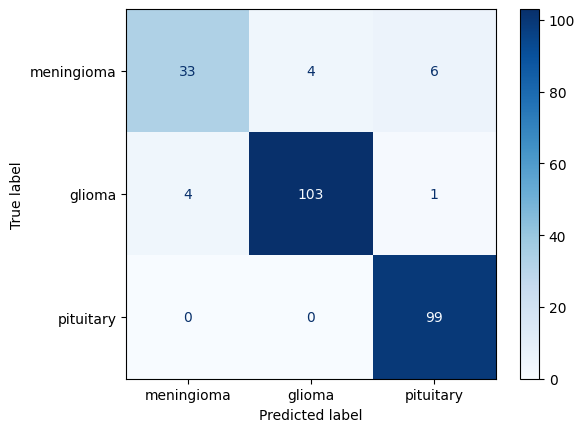

pid        class_name
102929     meningioma    6
107946     meningioma    4
92897      glioma        2
95142      glioma        2
MR051651B  glioma        1
dtype: int64


In [9]:
test_df = df.iloc[idx["test"]].copy()
test_probs = predict(baseline, idx["test"])
test_pred = test_probs.argmax(1)
test_true = y[idx["test"]].numpy()

print(classification_report(test_true, test_pred, target_names=class_names, digits=3))
pacc, npat, _ = patient_vote(test_df, test_probs)
print(f"test patient-level accuracy: {pacc:.3f} on {npat} patients")
print("95% interval for slice accuracy:", bootstrap_ci(test_df, test_probs).round(3))

ConfusionMatrixDisplay(confusion_matrix(test_true, test_pred),
                       display_labels=class_names).plot(cmap="Blues")
plt.savefig("/kaggle/working/test_confusion.png", dpi=150)
plt.show()

test_df["true"], test_df["pred"] = test_true, test_pred
test_df.to_csv("/kaggle/working/test_predictions.csv", index=False)
print(test_df[test_df.true != test_df.pred].groupby(["pid", "class_name"]).size())